# Phase 6 — SHAP explanations for the saved URL-only Random Forest

This analysis explains the existing Phase 5 candidate. It does not fit, tune, or alter the model. Global explanations use a deterministic sample from the held-out test partition. Local examples are selected from that sample. All URL features are produced by the canonical offline extractor.

## 1. Objective and reproducibility
The modeled positive class is `1 = phishing`; class `0 = legitimate`. Tree SHAP uses the Random Forest's tree-path statistics as its reference distribution. The sample seed is 2026.

In [1]:
from pathlib import Path
import json, os, sys, tempfile
PROJECT_ROOT = next(parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / 'src').is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'phishing-mpl-cache'))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from src.features import FEATURE_SCHEMA_VERSION
from src.ml.experiments import build_dataset, group_aware_three_way_split
from src.xai import URLShapExplainer

DATA_PATH = PROJECT_ROOT / 'data/raw/PhiUSIIL_Phishing_URL_Dataset.csv'
ARTIFACT_PATH = PROJECT_ROOT / 'models/url_only_random_forest_seed2026_candidate.joblib'
OUTPUT_DIR = PROJECT_ROOT / 'reports/xai'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026
print('SHAP:', shap.__version__)
print('Feature schema:', FEATURE_SCHEMA_VERSION)

SHAP: 0.54.1
Feature schema: 1.0.0


## 2. Load the Phase 5 candidate and verify its schema
The joblib artifact is loaded as-is. The feature names in the bundle must match the numeric feature fields in the canonical schema in the same order.

In [2]:
xai = URLShapExplainer.from_artifact(ARTIFACT_PATH)
print('Model:', type(xai.estimator).__name__)
print('Schema version:', xai.feature_schema_version)
print('Feature count/order:', len(xai.feature_names), xai.feature_names)
print('Classes:', xai.estimator.classes_)
print('SHAP explainer:', type(xai.explainer).__name__)
print('Configuration:', xai.explainer.model_output, xai.explainer.feature_perturbation)
assert xai.estimator.n_features_in_ == len(xai.feature_names)

Model: RandomForestClassifier
Schema version: 1.0.0
Feature count/order: 8 ('URLLength', 'DomainLength', 'IsDomainIP', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'IsHTTPS')
Classes: [0 1]
SHAP explainer: TreeExplainer
Configuration: raw tree_path_dependent


## 3. Rebuild the held-out test partition
Dataset inputs are reconstructed from each original URL using the Phase 4 extractor. We replay the saved Phase 5 group-aware 70/15/15 split (seed 2026) so exact duplicate URLs remain in one partition. The model is not fitted during this notebook.

In [3]:
dataset = build_dataset(DATA_PATH)
partitions = group_aware_three_way_split(dataset.X, dataset.y, dataset.urls, random_state=SEED)
test_idx = partitions['test']
X_test = dataset.X.iloc[test_idx].copy()
y_test = dataset.y.iloc[test_idx].copy()
urls_test = dataset.urls.iloc[test_idx].copy()
assert tuple(X_test.columns) == xai.feature_names
print('Test rows:', len(X_test), '| phishing:', int((y_test == 1).sum()), '| legitimate:', int((y_test == 0).sum()))
print('Duplicate URL groups stay within test by construction; no fitting or tuning is performed.')

Test rows: 35368 | phishing: 15142 | legitimate: 20226
Duplicate URL groups stay within test by construction; no fitting or tuning is performed.


## 4. Deterministic evaluation sample and SHAP values
For manageable, readable plots, take 300 rows per class from the held-out test set using seed 2026. This is an explanation/visualization sample only; it is not used for model fitting, model selection, or threshold tuning.

In [4]:
test_for_sample = X_test.assign(_target=y_test)
sampled = test_for_sample.groupby('_target', group_keys=False).sample(n=300, random_state=SEED).sort_index()
sample_idx = sampled.index
X_sample = X_test.loc[sample_idx, list(xai.feature_names)]
sample_probabilities, phishing_values, phishing_bases = xai.explain_frame(X_sample)
reconstructed = phishing_bases + phishing_values.sum(axis=1)
print('Sample rows:', len(X_sample), '| max additivity error:', float(np.max(np.abs(reconstructed - sample_probabilities))))
print('Explained output: raw TreeExplainer output for class 1; for this sklearn Random Forest it is the class probability.')

Sample rows: 600 | max additivity error: 3.6193270602780103e-14
Explained output: raw TreeExplainer output for class 1; for this sklearn Random Forest it is the class probability.


## 5. Global mean absolute SHAP importance
This is the mean absolute contribution magnitude for the phishing-class output over the selected test sample. It describes this fitted model's behavior on these rows and is not a causal or universal feature ranking.

In [5]:
global_importance = xai.global_importance(X_sample)
global_importance.to_csv(OUTPUT_DIR / 'global_shap_importance.csv', index=False)
display(global_importance)

,rank,feature,mean_abs_shap
0,1,IsHTTPS,0.222788
1,2,URLLength,0.174947
2,3,DomainLength,0.109532
3,4,NoOfDegitsInURL,0.094459
4,5,NoOfQMarkInURL,0.006345
5,6,NoOfEqualsInURL,0.003404
6,7,NoOfAmpersandInURL,0.000789
7,8,IsDomainIP,0.000034


## 6. Global SHAP plots
Both plots explain class `1 = phishing`. The beeswarm shows per-row contribution values and feature values; the bar plot summarizes mean absolute contributions.

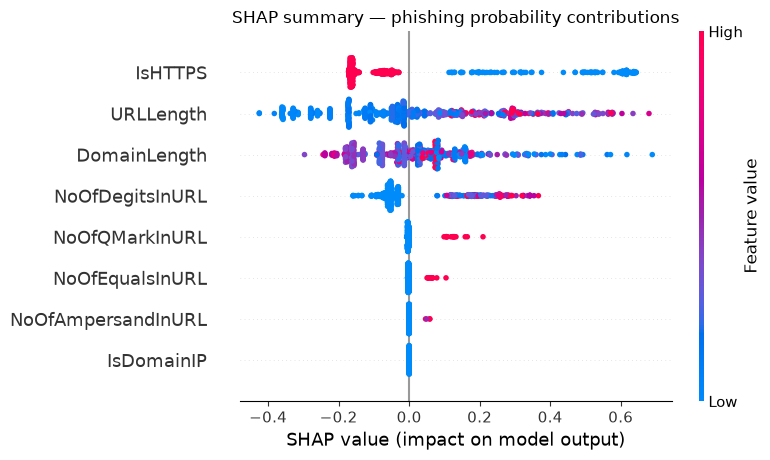

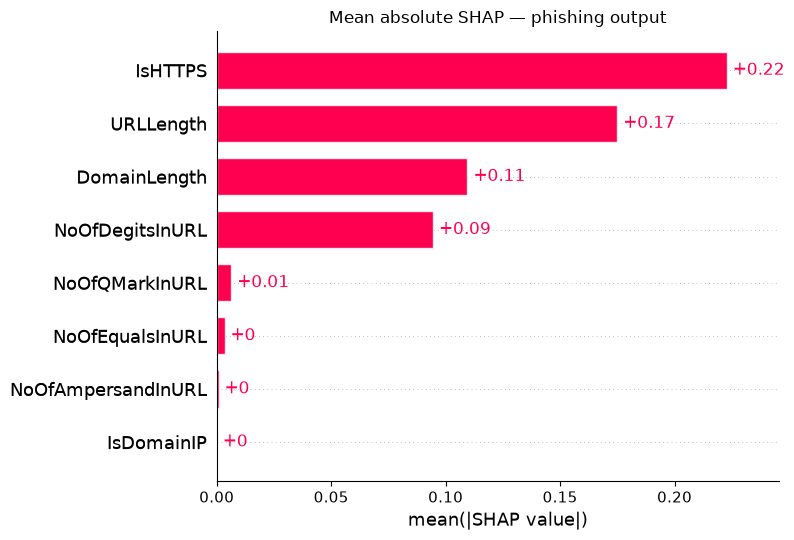

In [6]:
phishing_explanation = shap.Explanation(
    values=phishing_values, base_values=phishing_bases, data=X_sample.to_numpy(),
    feature_names=list(xai.feature_names)
)
shap.plots.beeswarm(phishing_explanation, max_display=len(xai.feature_names), show=False)
plt.title('SHAP summary — phishing probability contributions')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_summary_beeswarm.png', dpi=160, bbox_inches='tight')
plt.show()
shap.plots.bar(phishing_explanation, max_display=len(xai.feature_names), show=False)
plt.title('Mean absolute SHAP — phishing output')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_summary_bar.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Local phishing and legitimate examples
Choose the first correctly classified phishing and legitimate URL in the deterministic sample. The selected rows come from the held-out test partition; outputs are model explanations, not claims about the real-world status or causes of these URLs.

In [7]:
sample_targets = y_test.loc[sample_idx]
sample_predictions = (sample_probabilities >= 0.5).astype('int8')
phishing_positions = np.flatnonzero((sample_targets.to_numpy() == 1) & (sample_predictions == 1))
legitimate_positions = np.flatnonzero((sample_targets.to_numpy() == 0) & (sample_predictions == 0))
assert len(phishing_positions) and len(legitimate_positions), 'Expected both correctly classified classes in the sample'
phishing_row = int(phishing_positions[0])
legitimate_row = int(legitimate_positions[0])
phishing_example = xai.explain_url(str(urls_test.loc[sample_idx[phishing_row]]))
legitimate_example = xai.explain_url(str(urls_test.loc[sample_idx[legitimate_row]]))
print('Phishing example:')
print(json.dumps(phishing_example, indent=2, ensure_ascii=False, allow_nan=False))
print('Legitimate example:')
print(json.dumps(legitimate_example, indent=2, ensure_ascii=False, allow_nan=False))

Phishing example:
{
  "url": "https://page-review-0901513.firebaseapp.com/",
  "prediction": "phishing",
  "phishing_probability": 1.0,
  "threshold": 0.5,
  "positive_class": 1,
  "features": {
    "URLLength": 44,
    "DomainLength": 35,
    "IsDomainIP": 0,
    "NoOfDegitsInURL": 7,
    "NoOfEqualsInURL": 0,
    "NoOfQMarkInURL": 0,
    "NoOfAmpersandInURL": 0,
    "IsHTTPS": 1
  },
  "explanation": {
    "method": "SHAP TreeExplainer",
    "model_output": "raw",
    "feature_perturbation": "tree_path_dependent",
    "explained_class": 1,
    "shap_version": "0.54.1",
    "base_value": 0.4282660757775866,
    "shap_sum": 0.5717339242224108,
    "reconstructed_output": 0.9999999999999973,
    "model_phishing_probability": 1.0,
    "additivity_absolute_error": 2.6645352591003757e-15,
    "contributions": [
      {
        "feature": "URLLength",
        "value": 44,
        "shap_value": 0.27176283935226214,
        "direction": "phishing",
        "statement": "URLLength contributed 

## 8. Interpretation and consistency validation
Positive class-1 SHAP values increase the model's phishing output relative to its tree-path-dependent baseline; negative values decrease it. The additive identity is checked in the model's class-probability output space for this scikit-learn Random Forest. Feature attributions are model contributions and do not establish causality.

In [8]:
print('Max absolute additivity error over global sample:', float(np.max(np.abs(reconstructed - sample_probabilities))))
print('Phishing example reconstructed:', phishing_example['explanation']['reconstructed_output'])
print('Phishing example probability:', phishing_example['phishing_probability'])
print('Legitimate example reconstructed:', legitimate_example['explanation']['reconstructed_output'])
print('Legitimate example probability:', legitimate_example['phishing_probability'])
print('Generated:', sorted(p.name for p in OUTPUT_DIR.iterdir()))

Max absolute additivity error over global sample: 3.6193270602780103e-14
Phishing example reconstructed: 0.9999999999999973
Phishing example probability: 1.0
Legitimate example reconstructed: 0.005580002838540765
Legitimate example probability: 0.005580002838539063
Generated: ['global_shap_importance.csv', 'shap_summary_bar.png', 'shap_summary_beeswarm.png']


## 9. Limitations
- SHAP explains the fitted model, not the real-world cause of phishing.
- Correlated or redundant features can make individual attributions difficult to interpret.
- The model reflects one dataset and its extractor-defined feature representation.
- Explanations inherit the model and dataset's limitations.
- URL-only features cannot observe webpage content or behavior.
- A SHAP explanation does not validate whether a URL is actually malicious.
- Strong PhiUSIIL test performance does not establish universal real-world performance.
- `IsHTTPS` contributions are learned model behavior; HTTPS is not a safety guarantee.